# Multi-label-flipping data poisoning: две непересекающиеся атаки

Этот ноутбук повторяет структуру сценария `02_single_label_flip_comparison.ipynb`, но одновременно отравляет два непересекающихся класса: **1 → 7** и **2 → 8**. Для каждого вредоносного клиента часть образцов обоих исходных классов получает новую метку без изменения исходного датасета.

> Один парный запуск проверяет инфраструктуру. Для содержательного вывода об эффекте двух атак необходимы повторения на нескольких seed.

## 1. Параметры сценария и подготовка окружения

Контроль и атакованный запуск используют одинаковые модель, разбиение, гиперпараметры обучения и seed. Отличается только включённость multi-label-flip атаки.

In [1]:
import json
import os
import sys
from dataclasses import replace
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

try:
    from IPython.display import Markdown, display
except ImportError:
    Markdown = str
    def display(value):
        return value

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / 'pyproject.toml').exists():
    PROJECT_ROOT = next(path for path in [PROJECT_ROOT, *PROJECT_ROOT.parents] if (path / 'pyproject.toml').exists())
os.chdir(PROJECT_ROOT)
if str(PROJECT_ROOT / 'src') not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / 'src'))

from fl_benchmark.attacks.label_flip import build_label_flip_plan
from fl_benchmark.config import load_config
from fl_benchmark.datasets.loader import load_datasets
from fl_benchmark.datasets.partitioning import create_partitions, get_targets
from fl_benchmark.datasets.statistics import compute_partition_statistics
from fl_benchmark.task import run_local_simulation

BASE_CONFIG_PATH = PROJECT_ROOT / 'configs' / 'mnist_multi_label_flip.toml'
NOTEBOOK_RESULTS_DIR = PROJECT_ROOT / 'notebooks' / 'results'
NOTEBOOK_RESULTS_DIR.mkdir(parents=True, exist_ok=True)

base_config = load_config(BASE_CONFIG_PATH)
label_flips = base_config.attack.label_flips
clean_config = replace(
    base_config,
    name='mnist-multi-label-flip-clean-control',
    attack=replace(base_config.attack, enabled=False, type='none', malicious_fraction=0.0, poison_fraction=0.0, label_flips=()),
    tracking=replace(base_config.tracking, output_dir=NOTEBOOK_RESULTS_DIR, experiment_name='mnist-multi-label-flip-clean-control'),
    source_path=None,
)
attack_config = replace(
    base_config,
    name='mnist-multi-label-flip-attack',
    tracking=replace(base_config.tracking, output_dir=NOTEBOOK_RESULTS_DIR, experiment_name='mnist-multi-label-flip-attack'),
    source_path=None,
)

scenario_table = pd.DataFrame([
    ('Датасет', base_config.dataset.name),
    ('Модель / стратегия', f'{base_config.model.name} / {base_config.strategy.name}'),
    ('Клиенты / раунды', f'{base_config.partition.num_clients} / {base_config.federation.num_rounds}'),
    ('Non-IID режим', f'{base_config.partition.type}, alpha={base_config.partition.alpha}'),
    ('Отображения меток', ', '.join(f'{source} → {target}' for source, target in label_flips)),
    ('Вредоносные клиенты / доля отравления', f'{attack_config.attack.malicious_fraction:.0%} / {attack_config.attack.poison_fraction:.0%}'),
    ('Seed (разбиение / обучение / атака)', f'{base_config.partition.seed} / {base_config.training.seed} / {attack_config.attack.seed}'),
], columns=['Параметр', 'Значение'])
display(scenario_table)
print(f'Результаты: {NOTEBOOK_RESULTS_DIR}')

,Параметр,Значение
0,Датасет,mnist
1,Модель / стратегия,mnist-cnn / fedavg
2,Клиенты / раунды,10 / 5
3,Non-IID режим,"dirichlet, alpha=0.5"
4,Отображения меток,"1 → 7, 2 → 8"
5,Вредоносные клиенты / доля отравления,20% / 50%
6,Seed (разбиение / обучение / атака),42 / 42 / 42


Результаты: C:\Users\neko\Desktop\projects\fed-learning-stand\notebooks\results


## 2. Non-IID-разбиение и исходная статистика

Абсолютное и нормированное распределения классов показывают, чем отличаются клиенты. Entropy характеризует разнообразие локальных классов, а Jensen–Shannon divergence — отличие от глобального распределения.

,client_id,роль,num_examples,num_classes,entropy,js_divergence,max_class_fraction,imbalance_ratio
0,0,вредоносный,5669,10,2.763039,0.149579,0.266361,38.717949
1,1,честный,6558,10,1.947109,0.340865,0.421470,145.473684
2,2,честный,5193,10,2.805736,0.126478,0.279800,16.895349
3,3,честный,9858,10,2.701288,0.161481,0.263542,324.750000
4,4,честный,4116,10,2.853040,0.141588,0.215500,19.711111
5,5,честный,4606,10,2.929246,0.102907,0.256839,17.144928
6,6,честный,10756,10,2.579138,0.205664,0.290814,1042.666667
7,7,вредоносный,3576,10,2.136336,0.290717,0.456935,1634.000000
8,8,честный,5684,10,2.637645,0.195135,0.319669,90.850000
9,9,честный,3984,10,2.290201,0.263737,0.437500,871.500000


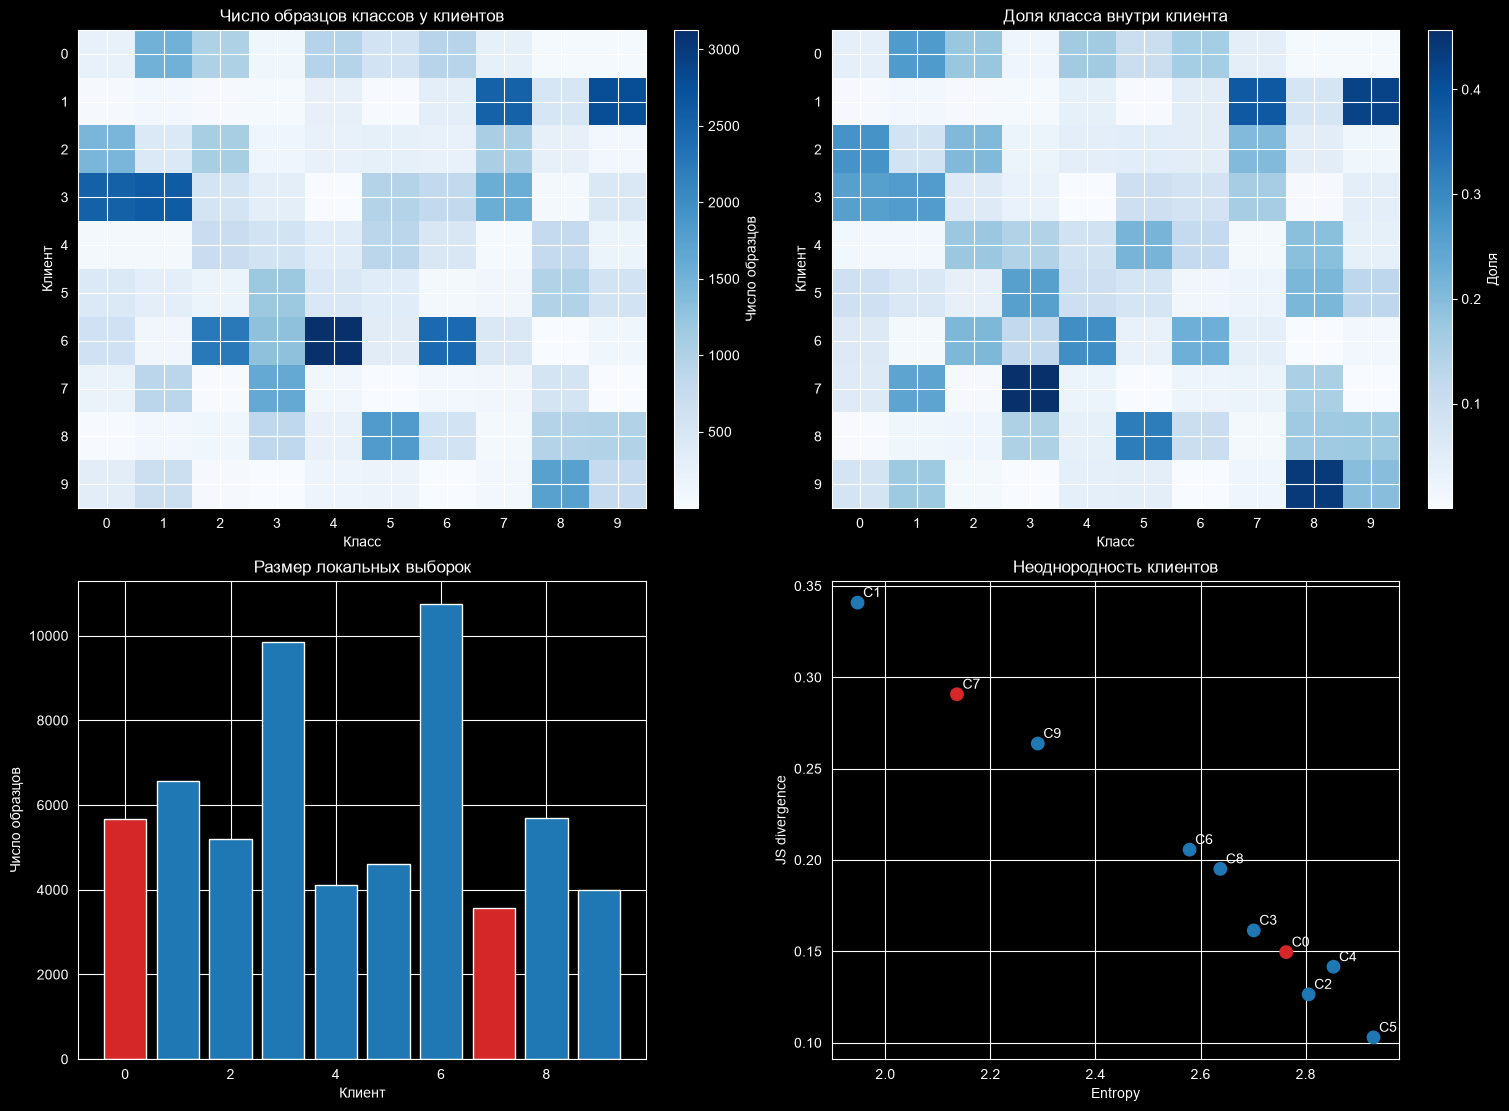

In [2]:
bundle = load_datasets(attack_config.dataset)
targets = get_targets(bundle.train)
partitions = create_partitions(bundle.train, attack_config.partition)
partition_statistics = compute_partition_statistics(targets, partitions, attack_config.model.num_classes)
attack_plan = build_label_flip_plan(targets, partitions, attack_config.attack)

stats = partition_statistics.statistics.copy().sort_values('client_id')
matrix = partition_statistics.matrix.copy().set_index('client_id')
malicious_clients = set(attack_plan.malicious_clients)
stats['роль'] = np.where(stats['client_id'].isin(malicious_clients), 'вредоносный', 'честный')
display(stats[['client_id', 'роль', 'num_examples', 'num_classes', 'entropy', 'js_divergence', 'max_class_fraction', 'imbalance_ratio']])

normalized_matrix = matrix.div(matrix.sum(axis=1), axis=0)
fig, axes = plt.subplots(2, 2, figsize=(15, 11), constrained_layout=True)
for axis, values, title, label in [
    (axes[0, 0], matrix.to_numpy(), 'Число образцов классов у клиентов', 'Число образцов'),
    (axes[0, 1], normalized_matrix.to_numpy(), 'Доля класса внутри клиента', 'Доля'),
]:
    image = axis.imshow(values, aspect='auto', cmap='Blues')
    axis.set(title=title, xlabel='Класс', ylabel='Клиент', xticks=range(attack_config.model.num_classes), yticks=range(len(matrix)))
    fig.colorbar(image, ax=axis, label=label)
colors = ['tab:red' if client_id in malicious_clients else 'tab:blue' for client_id in stats['client_id']]
axes[1, 0].bar(stats['client_id'], stats['num_examples'], color=colors)
axes[1, 0].set(title='Размер локальных выборок', xlabel='Клиент', ylabel='Число образцов')
axes[1, 1].scatter(stats['entropy'], stats['js_divergence'], c=colors, s=80)
for row in stats.itertuples():
    axes[1, 1].annotate(f'C{row.client_id}', (row.entropy, row.js_divergence), xytext=(4, 4), textcoords='offset points')
axes[1, 1].set(title='Неоднородность клиентов', xlabel='Entropy', ylabel='JS divergence')
plt.show()

## 3. План двух label-flip атак

Одни и те же вредоносные клиенты отравляют примеры каждого исходного класса независимо. Классы отображений не пересекаются: объект класса `1` никогда не участвует в отображении `2 → 8` и наоборот.

,клиент,отображение,исходных примеров,изменено меток,доля
0,0,1 → 7,1510,755,50.0%
1,0,2 → 8,1007,504,50.0%
2,7,1 → 7,883,442,50.1%
3,7,2 → 8,18,9,50.0%


{
  "enabled": true,
  "type": "multi_label_flip",
  "seed": 42,
  "malicious_fraction": 0.2,
  "poison_fraction": 0.5,
  "source_label": 0,
  "target_label": 1,
  "label_flips": [
    {
      "source_label": 1,
      "target_label": 7
    },
    {
      "source_label": 2,
      "target_label": 8
    }
  ],
  "malicious_clients": [
    0,
    7
  ],
  "num_malicious_clients": 2,
  "poisoned_examples_per_client": {
    "0": 1259,
    "7": 451
  },
  "total_poisoned_examples": 1710,
  "poisoned_examples_by_flip": {
    "1->7": 1197,
    "2->8": 513
  }
}


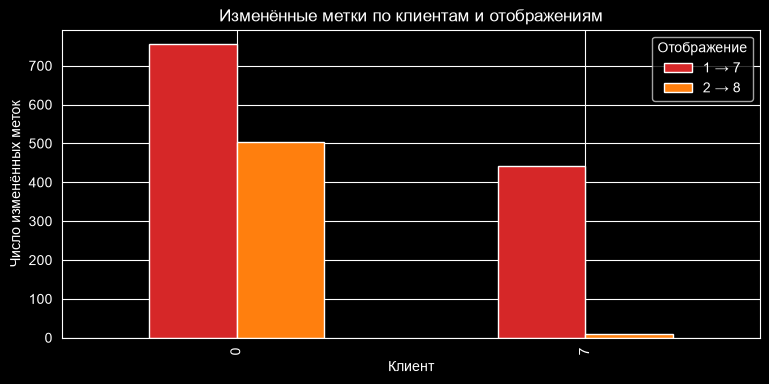

In [3]:
manifest = attack_plan.manifest()
attack_rows = []
for client_id in attack_plan.malicious_clients:
    local_indices = np.asarray(partitions[client_id], dtype=int)
    for source_label, target_label in label_flips:
        source_count = int((targets[local_indices] == source_label).sum())
        poisoned_count = sum(target == target_label for target in attack_plan.target_labels_by_index[client_id].values())
        attack_rows.append({'клиент': client_id, 'отображение': f'{source_label} → {target_label}', 'исходных примеров': source_count, 'изменено меток': poisoned_count, 'доля': poisoned_count / source_count if source_count else 0.0})
attack_table = pd.DataFrame(attack_rows)
display(attack_table.style.format({'доля': '{:.1%}'}))
print(json.dumps({key: value for key, value in manifest.items() if key != 'poisoned_indices'}, ensure_ascii=False, indent=2))

if attack_table.empty or attack_plan.total_poisoned_examples == 0:
    raise RuntimeError('В текущем плане нет отравлённых примеров.')
fig, axis = plt.subplots(figsize=(9, 4))
pivot = attack_table.pivot(index='клиент', columns='отображение', values='изменено меток')
pivot.plot(kind='bar', ax=axis, color=['tab:red', 'tab:orange'])
axis.set(title='Изменённые метки по клиентам и отображениям', xlabel='Клиент', ylabel='Число изменённых меток')
axis.legend(title='Отображение')
plt.show()

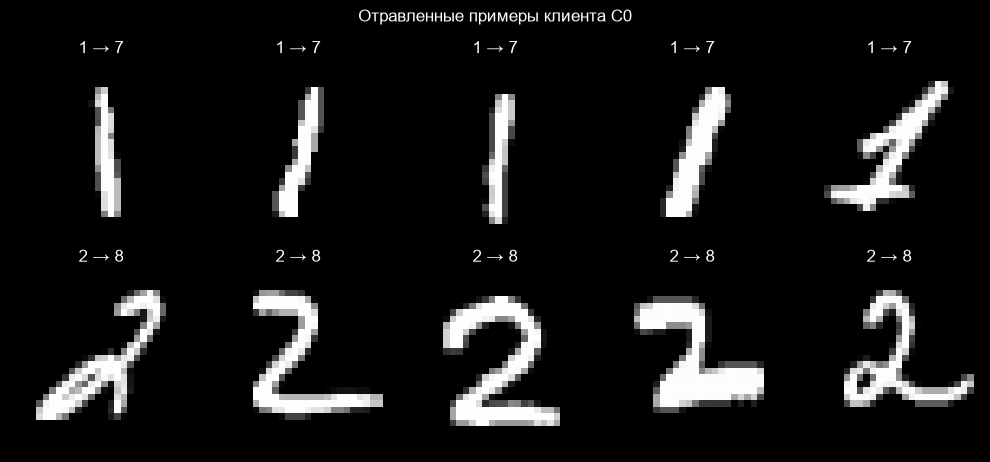

In [4]:
client_id = attack_plan.malicious_clients[0]
fig, axes = plt.subplots(len(label_flips), 5, figsize=(10, 2.4 * len(label_flips)), squeeze=False)
for row, (source_label, target_label) in enumerate(label_flips):
    poisoned = [index for index, target in attack_plan.target_labels_by_index[client_id].items() if target == target_label][:5]
    for axis, sample_index in zip(axes[row], poisoned, strict=False):
        image, true_label = bundle.train[sample_index]
        axis.imshow(image.squeeze(), cmap='gray')
        axis.set_title(f'{true_label} → {target_label}')
        axis.axis('off')
    for axis in axes[row, len(poisoned):]:
        axis.axis('off')
    axes[row, 0].set_ylabel(f'Класс {source_label}', rotation=0, labelpad=35, va='center')
fig.suptitle(f'Отравленные примеры клиента C{client_id}')
plt.tight_layout()
plt.show()

## 4. Полный парный запуск

Запускаются две симуляции на полном MNIST: чистый контроль и multi-label-flip. Каталоги запусков создаются в `notebooks/results/` и не перезаписывают прежние результаты.

In [5]:
RUN_FULL_EXPERIMENTS = True

if RUN_FULL_EXPERIMENTS:
    print('Запуск 1/2: чистый контрольный сценарий...')
    clean_output_dir = run_local_simulation(clean_config)
    print(f'Готово: {clean_output_dir}')
    print('Запуск 2/2: две label-flip атаки...')
    attack_output_dir = run_local_simulation(attack_config)
    print(f'Готово: {attack_output_dir}')
else:
    def latest_result(prefix):
        candidates = sorted(NOTEBOOK_RESULTS_DIR.glob(f'{prefix}-*'), key=lambda path: path.stat().st_mtime)
        if not candidates:
            raise FileNotFoundError(f'Не найдены результаты {prefix!r}')
        return candidates[-1]
    clean_output_dir = latest_result('mnist-multi-label-flip-clean-control')
    attack_output_dir = latest_result('mnist-multi-label-flip-attack')
    print(f'Используются результаты:\n  clean: {clean_output_dir}\n  attack: {attack_output_dir}')

Запуск 1/2: чистый контрольный сценарий...
Готово: C:\Users\neko\Desktop\projects\fed-learning-stand\notebooks\results\mnist-multi-label-flip-clean-control-20261124-185455-3fb3a16e
Запуск 2/2: две label-flip атаки...
Готово: C:\Users\neko\Desktop\projects\fed-learning-stand\notebooks\results\mnist-multi-label-flip-attack-20261124-185806-3dc0472d


## 5. Сопоставление обучения и итоговых метрик

Глобальные кривые демонстрируют общую динамику обучения. Поклассовая диаграмма показывает, как изменилось качество именно для четырёх классов, затронутых двумя отображениями.

,Метрика,Контроль,Две атаки,Изменение (атака − контроль)
0,Итоговая accuracy,0.97310,0.97380,+0.00070
1,Итоговый loss,0.08500,0.08745,+0.00244
2,Итоговый macro F1,0.97285,0.97360,+0.00075
3,"Время выполнения, с",186.29858,184.03125,-2.26732
4,"Передано данных, байт",42346400.00000,42346400.00000,+0.00000


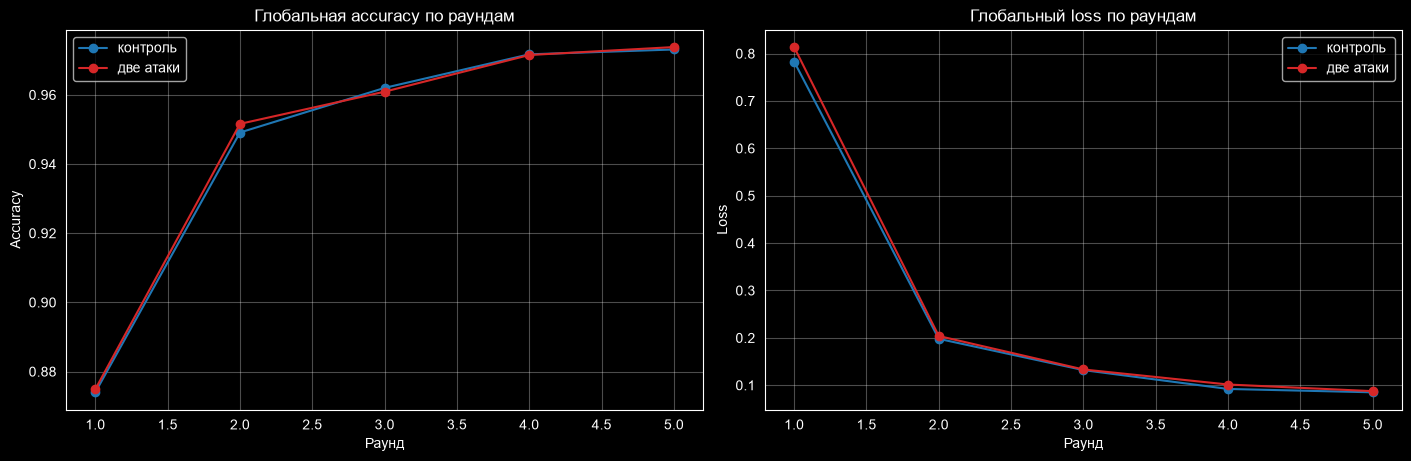

In [6]:
def load_run(output_dir):
    confusion = pd.read_csv(output_dir / 'final_confusion_matrix.csv').to_numpy()
    per_class_path = output_dir / 'final_per_class_metrics.csv'
    if per_class_path.exists():
        per_class = pd.read_csv(per_class_path)
    else:
        support = confusion.sum(axis=1)
        per_class = pd.DataFrame({'class_id': np.arange(len(support)), 'support': support, 'accuracy': np.divide(np.diag(confusion), support, out=np.zeros_like(support, dtype=float), where=support != 0), 'loss': np.nan})
    return {'path': output_dir, 'summary': json.loads((output_dir / 'summary.json').read_text(encoding='utf-8')), 'rounds': pd.read_csv(output_dir / 'round_metrics.csv'), 'clients': pd.read_csv(output_dir / 'client_metrics.csv'), 'confusion': confusion, 'per_class': per_class, 'manifest': json.loads((output_dir / 'attack_manifest.json').read_text(encoding='utf-8'))}

clean_run = load_run(clean_output_dir)
attack_run = load_run(attack_output_dir)
comparison = pd.DataFrame([
    ('Итоговая accuracy', clean_run['summary']['final_accuracy'], attack_run['summary']['final_accuracy']),
    ('Итоговый loss', clean_run['summary']['final_loss'], attack_run['summary']['final_loss']),
    ('Итоговый macro F1', clean_run['summary']['final_macro_f1'], attack_run['summary']['final_macro_f1']),
    ('Время выполнения, с', clean_run['summary']['total_duration_seconds'], attack_run['summary']['total_duration_seconds']),
    ('Передано данных, байт', clean_run['summary']['total_communication_bytes'], attack_run['summary']['total_communication_bytes']),
], columns=['Метрика', 'Контроль', 'Две атаки'])
comparison['Изменение (атака − контроль)'] = comparison['Две атаки'] - comparison['Контроль']
display(comparison.style.format({'Контроль': '{:.5f}', 'Две атаки': '{:.5f}', 'Изменение (атака − контроль)': '{:+.5f}'}))
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), constrained_layout=True)
for run, label, color in [(clean_run, 'контроль', 'tab:blue'), (attack_run, 'две атаки', 'tab:red')]:
    axes[0].plot(run['rounds']['round'], run['rounds']['global_accuracy'], marker='o', label=label, color=color)
    axes[1].plot(run['rounds']['round'], run['rounds']['global_loss'], marker='o', label=label, color=color)
axes[0].set(title='Глобальная accuracy по раундам', xlabel='Раунд', ylabel='Accuracy')
axes[1].set(title='Глобальный loss по раундам', xlabel='Раунд', ylabel='Loss')
for axis in axes:
    axis.grid(alpha=0.3)
    axis.legend()
plt.show()

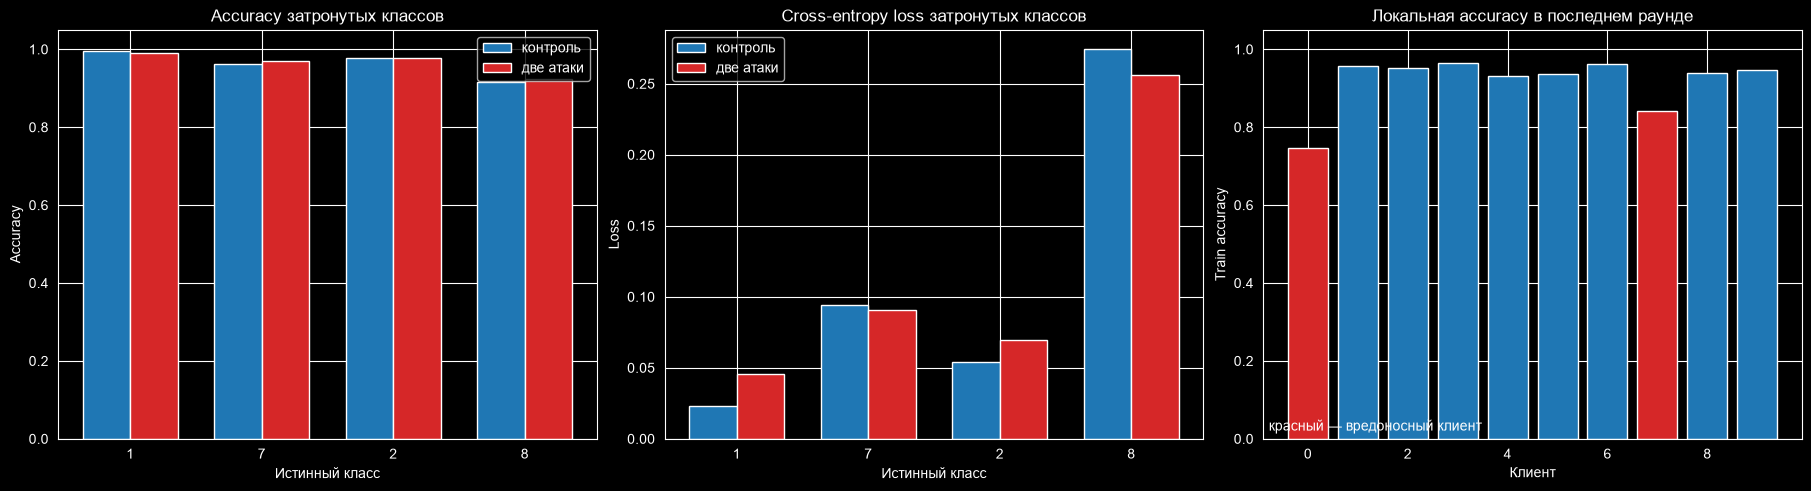

,класс,контрольная accuracy,accuracy при атаке,контрольный loss,loss при атаке,изменение accuracy,изменение loss
0,1,99.559%,98.943%,0.02290,0.04527,-0.617%,+0.02237
1,7,96.304%,96.887%,0.09416,0.09079,+0.584%,-0.00337
2,2,97.771%,97.771%,0.05416,0.06938,+0.000%,+0.01523
3,8,91.478%,92.402%,0.27423,0.25641,+0.924%,-0.01782


In [7]:
focus_classes = [label for pair in label_flips for label in pair]
clean_focus = clean_run['per_class'].set_index('class_id').reindex(focus_classes)
attack_focus = attack_run['per_class'].set_index('class_id').reindex(focus_classes)
final_client_metrics = attack_run['clients'].sort_values('round').groupby('partition_id', as_index=False).tail(1)
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8), constrained_layout=True)
width = 0.36
x = np.arange(len(focus_classes))
axes[0].bar(x - width / 2, clean_focus['accuracy'], width, label='контроль', color='tab:blue')
axes[0].bar(x + width / 2, attack_focus['accuracy'], width, label='две атаки', color='tab:red')
axes[0].set(title='Accuracy затронутых классов', xlabel='Истинный класс', ylabel='Accuracy', xticks=x, xticklabels=focus_classes, ylim=(0, 1.05))
axes[0].legend()
if clean_focus['loss'].isna().any() or attack_focus['loss'].isna().any():
    axes[1].text(0.5, 0.5, 'Class-wise loss отсутствует в старых результатах.\nЗапустите сценарий заново.', ha='center', va='center', transform=axes[1].transAxes)
    axes[1].set_axis_off()
else:
    axes[1].bar(x - width / 2, clean_focus['loss'], width, label='контроль', color='tab:blue')
    axes[1].bar(x + width / 2, attack_focus['loss'], width, label='две атаки', color='tab:red')
    axes[1].set(title='Cross-entropy loss затронутых классов', xlabel='Истинный класс', ylabel='Loss', xticks=x, xticklabels=focus_classes)
    axes[1].legend()
client_colors = np.where(final_client_metrics['is_malicious'], 'tab:red', 'tab:blue')
axes[2].bar(final_client_metrics['partition_id'], final_client_metrics['train_accuracy'], color=client_colors)
axes[2].set(title='Локальная accuracy в последнем раунде', xlabel='Клиент', ylabel='Train accuracy', ylim=(0, 1.05))
axes[2].text(0.01, 0.02, 'красный — вредоносный клиент', transform=axes[2].transAxes)
plt.show()
focus = pd.DataFrame({'класс': focus_classes, 'контрольная accuracy': clean_focus['accuracy'].to_numpy(), 'accuracy при атаке': attack_focus['accuracy'].to_numpy(), 'контрольный loss': clean_focus['loss'].to_numpy(), 'loss при атаке': attack_focus['loss'].to_numpy()})
focus['изменение accuracy'] = focus['accuracy при атаке'] - focus['контрольная accuracy']
focus['изменение loss'] = focus['loss при атаке'] - focus['контрольный loss']
display(focus.style.format({'контрольная accuracy': '{:.3%}', 'accuracy при атаке': '{:.3%}', 'контрольный loss': '{:.5f}', 'loss при атаке': '{:.5f}', 'изменение accuracy': '{:+.3%}', 'изменение loss': '{:+.5f}'}))

## 6. Сводка, артефакты и границы вывода

Сводка фиксирует фактически применённые отображения и разницу метрик. Она не заменяет статистический анализ серии запусков.

In [8]:
delta_accuracy = attack_run['summary']['final_accuracy'] - clean_run['summary']['final_accuracy']
delta_loss = attack_run['summary']['final_loss'] - clean_run['summary']['final_loss']
mapping_text = ', '.join(f'{item["source_label"]} → {item["target_label"]}' for item in attack_run['manifest']['label_flips'])
display(Markdown(f'''
### Итог одного парного запуска

- Контроль: accuracy **{clean_run['summary']['final_accuracy']:.4f}**, loss **{clean_run['summary']['final_loss']:.4f}**.
- Две атаки ({mapping_text}): accuracy **{attack_run['summary']['final_accuracy']:.4f}**, loss **{attack_run['summary']['final_loss']:.4f}**.
- Разность «атака − контроль»: accuracy **{delta_accuracy:+.4f}**, loss **{delta_loss:+.4f}**.
- Отравлено **{attack_run['manifest']['total_poisoned_examples']}** меток у **{attack_run['manifest']['num_malicious_clients']}** клиентов.

Следующий шаг — повторить эту пару сценариев минимум для трёх seed и сравнить среднее значение, стандартное отклонение и доверительные интервалы.
'''))
display(pd.DataFrame([
    ('Контрольный запуск', str(clean_run['path'])),
    ('Атакованный запуск', str(attack_run['path'])),
    ('План атаки', 'attack_manifest.json'),
    ('Метрики по раундам', 'round_metrics.csv'),
    ('Поклассовая диагностика', 'final_confusion_matrix.csv'),
], columns=['Артефакт', 'Расположение']))


### Итог одного парного запуска

- Контроль: accuracy **0.9731**, loss **0.0850**.
- Две атаки (1 → 7, 2 → 8): accuracy **0.9738**, loss **0.0874**.
- Разность «атака − контроль»: accuracy **+0.0007**, loss **+0.0024**.
- Отравлено **1710** меток у **2** клиентов.

Следующий шаг — повторить эту пару сценариев минимум для трёх seed и сравнить среднее значение, стандартное отклонение и доверительные интервалы.


,Артефакт,Расположение
0,Контрольный запуск,C:\Users\neko\Desktop\projects\fed-learning-st...
1,Атакованный запуск,C:\Users\neko\Desktop\projects\fed-learning-st...
2,План атаки,attack_manifest.json
3,Метрики по раундам,round_metrics.csv
4,Поклассовая диагностика,final_confusion_matrix.csv
